# RQ2: Precipitation vs. Audio Features

**Research Question:** In what ways does high daily precipitation influence the preference for 'Acoustic' vs. 'High-Energy' tracks in the German charts?

---

## 1. Methods

Daily precipitation was categorized into four ordinal levels using percentile cutoffs (25th, 50th, 75th percentiles), producing **No rain**, **Low**, **Moderate**, and **High** categories, each containing an approximate same number of observations (about 20,000 per category). Daily precipitation is famously non-normal, most days 0mm, somedays ~ 0.5mm or rarely 50mm hence this highly skewed dataset, using percentile-based bucketing ensures enough data for the analysis.

The following tests were conducted for every audio feature:

- **Kruskal-Wallis H-test**:— nonparametric one-way analysis of variance that allows detecting whether medians are statistically significantly different among precipitation groups. This approach is robust to violations of normal distribution and outliers typical of audio features.
- **Dunn's post hoc test with Bonferroni correction** — used to find out which particular groups of precipitation are statistically significantly different.
- **Epsilon-squared (ε²)**:— computed as `H / (n - 1)` to evaluate the practical significance of an observed effect (negligible / small / moderate / large). The Effect-Size bins was drived from Cohen's (1988) benchmarks adapted for non-parametric tests. As the dataset is large we might experience a statistically significance but if we account for the size of the dataset we can calculate for practical significance. 

- **Spearman's rank-order correlation**:— between continuous `precipitation_mm` and an audio feature to get the measure of monotonic relationship (rho, 95% CI, direction).

In [210]:
# Load result JSONs produced by the Snakemake workflow
import json
import os
import pandas as pd
from IPython.display import Image, display
RESULTS_DIR = "../results/workflow_2"
FEATURES = ["acousticness", "danceability", "tempo", "energy", "valence"]

kruskal_results = {}
spearman_results = {}

for feature in FEATURES:
    kruskal_path = os.path.join(RESULTS_DIR, f"kruskal_{feature}.json")
    spearman_path = os.path.join(RESULTS_DIR, f"spearman_{feature}.json")
    if os.path.exists(kruskal_path):
        with open(kruskal_path) as f:
            kruskal_results[feature] = json.load(f)
    if os.path.exists(spearman_path):
        with open(spearman_path) as f:
            spearman_results[feature] = json.load(f)

print("Loaded results for:", list(kruskal_results.keys()))

Loaded results for: ['acousticness', 'danceability', 'tempo', 'energy', 'valence']


In [211]:
# Summary table: Kruskal-Wallis results across all features
rows = []
for feature, r in kruskal_results.items():
    rows.append({
        "Feature": feature,
        "H statistic": r["h_statistic"],
        "p-value": r["p_value"],
        "Significant": r["significant_at_0.05"],
        "ε² (epsilon-squared)": r["effect_size"]["epsilon_squared"],
        "Effect label": r["effect_size"]["label"],
    })

kruskal_summary = pd.DataFrame(rows)
kruskal_summary

,Feature,H statistic,p-value,Significant,ε² (epsilon-squared),Effect label
0,acousticness,5.3589,0.147326,False,0.0029,negligible
1,danceability,10.4538,0.015077,True,0.0057,negligible
2,tempo,7.6157,0.054660,False,0.0042,negligible
3,energy,2.1558,0.540701,False,0.0012,negligible
4,valence,4.3791,0.223327,False,0.0024,negligible


In [212]:
#Percentile Cutoffs for precipitation_mm
df = pd.read_csv("../data/spotify_weather_merged_processed_w2.csv")
for p in [25, 50, 75]:
    print(f"{p}th percentile: {df['precipitation_mm'].quantile(p/100):.2f} mm/day")
    print('\n')
print(f"Max: {df['precipitation_mm'].max():.2f} mm/day")


25th percentile: 0.14 mm/day


50th percentile: 0.97 mm/day


75th percentile: 2.92 mm/day


Max: 22.44 mm/day


In [213]:
# Summary table: Spearman results across all features
rows = []
for feature, r in spearman_results.items():
    ci = r.get("ci_95", [None, None])
    rows.append({
        "Feature": feature,
        "rho": r["rho"],
        "p-value": r["p_value"],
        "Significant": r["significant_at_0.05"],
        "Direction": r["direction"],
        "Effect size": r["effect_size"],
        "95% CI lower": ci[0],
        "95% CI upper": ci[1],
    })

spearman_summary = pd.DataFrame(rows)
spearman_summary

,Feature,rho,p-value,Significant,Direction,Effect size,95% CI lower,95% CI upper
0,acousticness,-0.0454,0.052342,False,negative,negligible,-0.0911,0.0005
1,danceability,-0.0802,0.000600,True,negative,negligible,-0.1256,-0.0345
2,tempo,0.0607,0.009530,True,positive,negligible,0.0148,0.1062
3,energy,-0.0243,0.299135,False,negative,negligible,-0.0701,0.0216
4,valence,0.0148,0.526609,False,positive,negligible,-0.0311,0.0607


---
## 2. Findings

 2.0 Group Summary Statistics.

In [214]:
# Full group summary: n, median, Q1, Q3 per bucket per feature
rows = []
for feature, r in kruskal_results.items():
    for bucket, stats in r["group_summary"].items():
        rows.append({
            "Feature": feature,
            "Bucket": bucket,
            "n": stats["n"],
            "Median": stats["median"],
            "Q1": stats["q1"],
            "Q3": stats["q3"],
        })

summary_df = pd.DataFrame(rows)
summary_df.pivot_table(
    index=["Feature", "Bucket"],
    values=["n", "Median", "Q1", "Q3"]
).round(4)

Median        Q1        Q3      n
Feature      Bucket                                       
acousticness High        0.1982    0.1692    0.2190  459.0
             Low         0.1987    0.1763    0.2217  454.0
             Moderate    0.1978    0.1738    0.2180  466.0
             No rain     0.2008    0.1801    0.2193  447.0
danceability High        0.6811    0.6682    0.6958  459.0
             Low         0.6844    0.6717    0.6950  454.0
             Moderate    0.6840    0.6708    0.6956  466.0
             No rain     0.6854    0.6737    0.6976  447.0
energy       High        0.6727    0.6559    0.6892  459.0
             Low         0.6715    0.6542    0.6866  454.0
             Moderate    0.6735    0.6563    0.6907  466.0
             No rain     0.6766    0.6541    0.6908  447.0
tempo        High      118.3508  114.8013  121.2084  459.0
             Low       117.1922  114.2008  120.5724  454.0
             Moderate  117.3878  114.3652  120.7249  466.0
             No rain   117.1562  114.1552  120.6445  447.0
valence      High        0.4978    0.4778    0.5159  459.0
             Low         0.4932    0.4740    0.5153  454.0
             Moderate    0.4943    0.4741    0.5119  466.0
             No rain     0.4962    0.4789    0.5108  447.0

### **2.1 Acousticness**

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 5.36, p = 0.1473  **not significant** |
| Effect size | ε² = 0.0029  **negligible** |
| Significant pairs (Dunn's) | None (omnibus test not significant) |
| Spearman rho | −0.0454, p = 0.0523, 95% CI [−0.0911, 0.0005] |
| Direction | **negative**  acousticness decreases slightly as precipitation increases |

The confidence interval crosses zero, so the direction is not statistically reliable.

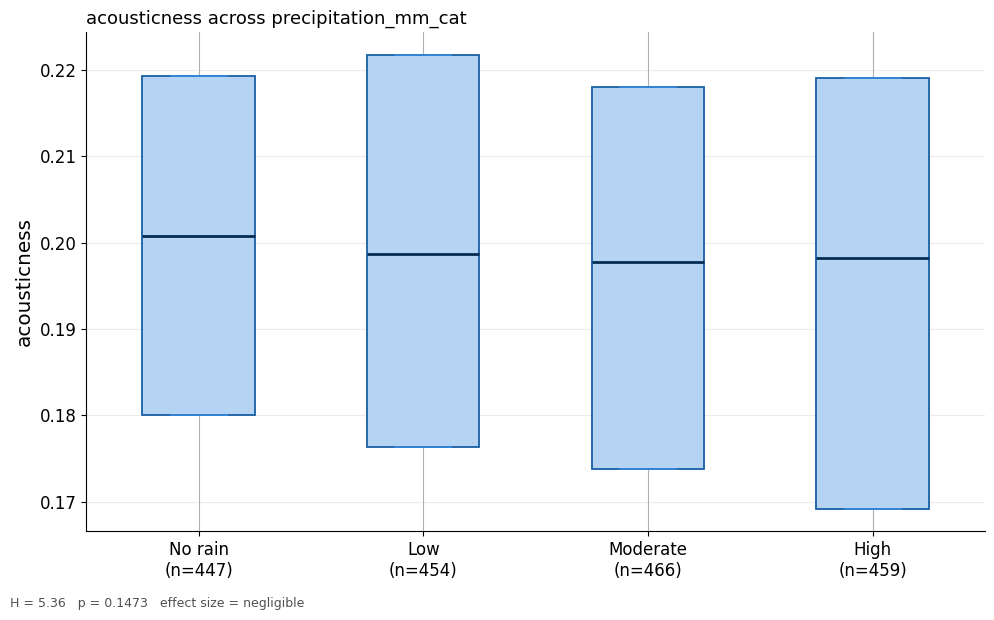

In [227]:
# Display acousticness Kruskal-Wallis box plot report
Image(os.path.join(RESULTS_DIR, "kruskal_report_acousticness.png"))

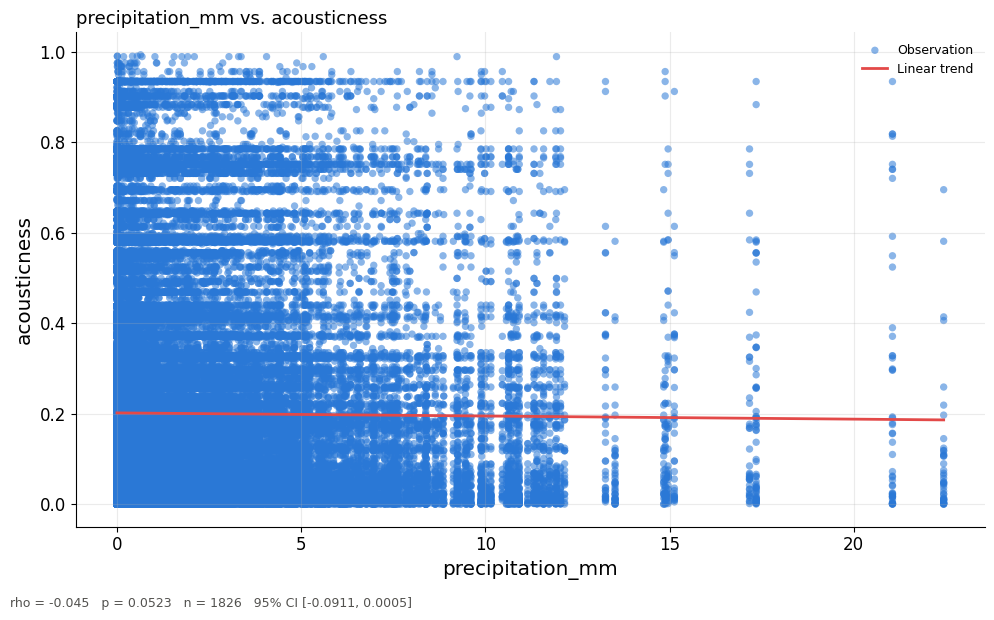

In [228]:
#Display acousticness Spearman correlation report
Image(os.path.join(RESULTS_DIR, "spearman_report_acousticness.png"))

- **Interpretation**

The value of H = 5.36 fails to pass the threshold of significance (p = 0.1473). Given the sample size of 1,826 independent days, one would expect much higher values of H in case the effect was strong enough. P-value shows that there are no significant differences between levels of acousticness with respect to precipitation categories using daily data. The variance in acousticness can be explained by 0.29% of the variance in precipitation category (ε² = 0.0029).

Since the results of Kruskal-Wallis test were insignificant, there were no post hoc pairwise comparisons made. The absence of significant differences shows that acousticness does not react to changes in precipitation categories.

The Spearman's rank correlation coefficient shows an extremely weak and non-significant negative correlation (ρ = −0.0454, p = 0.0523). Continuous data on precipitation do not show a relationship since the confidence interval includes zero (95% CI [−0.0911, 0.0005]). Linear trend is virtually flat for 1,826 daily observations. This confirms that although ρ = −0.045 is negative, it is statistically insignificant and the actual effect is absent. There is no relationship between acousticness and precipitation.

### **2.2 Danceability**

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 10.45, p = 0.0151  **significant** |
| Effect size | ε² = 0.0057  **negligible** |
| Significant pairs (Dunn's) | No rain vs. High (p = 0.0074), all other pairs not significant |
| Spearman rho | −0.0802, p = 0.0006, 95% CI [−0.1256, −0.0345] |
| Direction | negative, danceability decreases slightly as precipitation increases |

While statistically significant, the effect size is negligible in both tests. The only meaningful categorical difference is between No rain and High precipitation days.

In [238]:
# Full pairwise Dunn's post-hoc table for danceability
posthoc = kruskal_results["danceability"]["posthoc_pairwise_p"]
posthoc_df = pd.DataFrame([
    {"Comparison": k.replace("_vs_", " vs. "),
     "Adjusted p-value": v,
     "Significant": "Yes" if v < 0.05 else "No"}
    for k, v in posthoc.items()
])
posthoc_df

,Comparison,Adjusted p-value,Significant
0,No rain vs. Low,0.6926,No
1,No rain vs. Moderate,0.6490,No
2,No rain vs. High,0.0074,Yes
3,Low vs. Moderate,1.0000,No
4,Low vs. High,0.5809,No
5,Moderate vs. High,0.5948,No


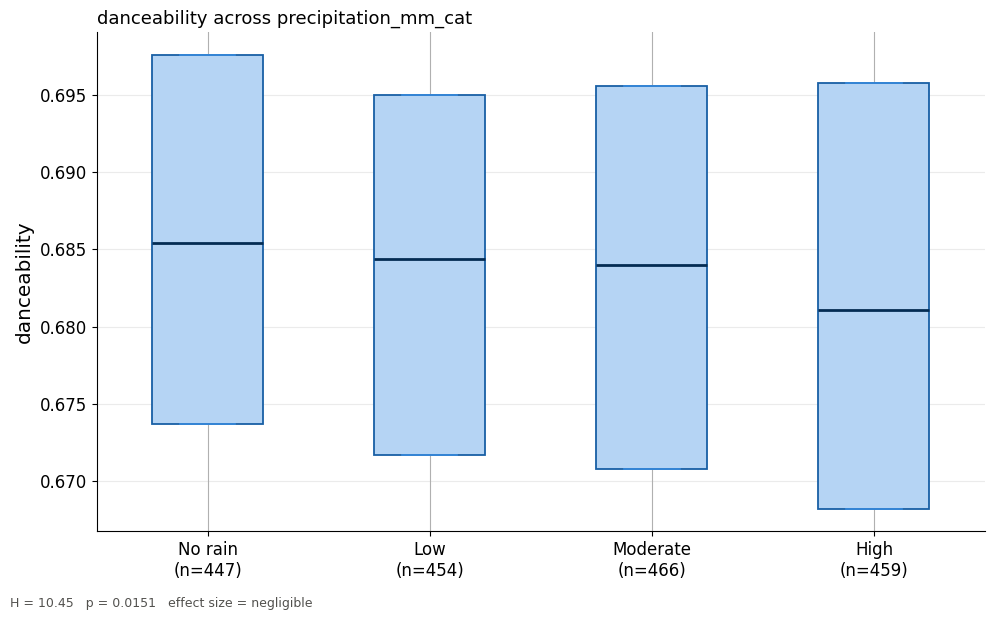

In [239]:
Image(os.path.join(RESULTS_DIR, "kruskal_report_danceability.png"))

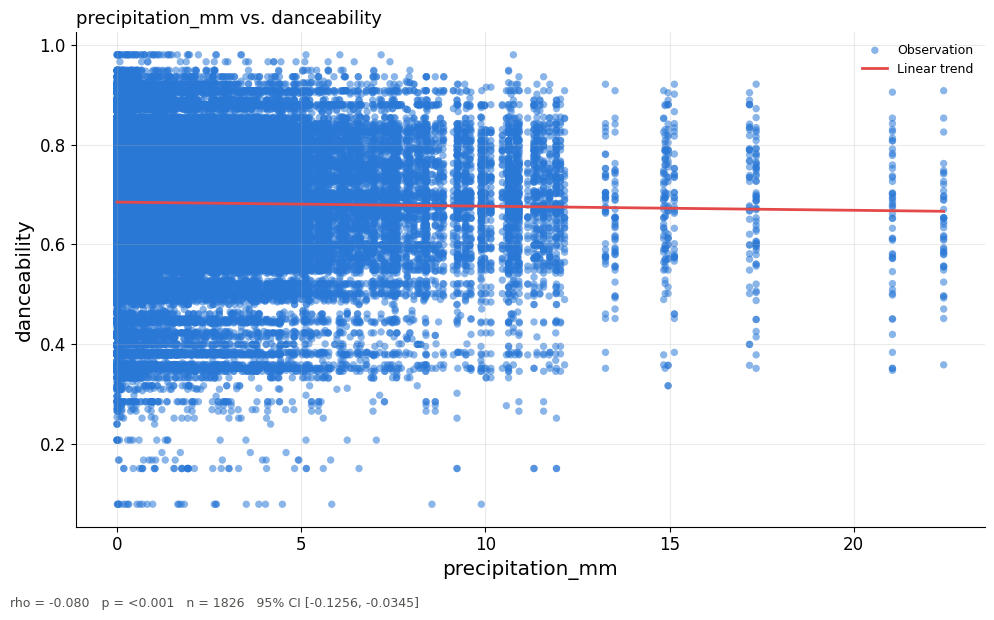

In [240]:
#Display danceability Spearman correlation report
Image(os.path.join(RESULTS_DIR, "spearman_report_danceability.png"))

- **Interpretation**

There was a significant difference in groups depending on the precipitation (H = 10.45, p = 0.0151); however, the effect size was trivial (ε² = 0.0057).

The only significant difference in pairs is the pair of No rain and High precipitation (adjusted p = 0.0074), while all other pairs are insignificant, indicating that there might be a threshold effect rather than a continuous one.

There was a very small but statistically significant negative correlation (ρ = −0.0802, p = 0.0006). Even though the direction is consistent, the effect size is trivial. The confidence interval is located completely in the negative range (95% CI [−0.1256, −0.0345]), which proves the direction with 95% confidence.

Similar to the acousticness, the trend line is a straight horizontal line through 1,826 daily observations, confirming that even though ρ = −0.080 is statistically significant, there is no practical effect. Thus, there is no practical response to the precipitation of any intensity.

The only change in the median value of danceability is marginal, changing from 0.6854 (No rain) to 0.6811 (High), the difference being only −0.0043.

### **2.3 Tempo**

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 7.62, p = 0.0547  ***not significant** very close tho |
| Effect size | ε² = 0.0042  **negligible** |
| Significant pairs (Dunn's) | None (omnibus test not significant) |
| Spearman rho | 0.0607, p = 0.0095, 95% CI [0.0148, 0.1062] |
| Direction | positive tempo increases very slightly as precipitation increases |

The Kruskal‑Wallis test narrowly misses significance (p = 0.055), but the Spearman correlation is significant with a confidence interval entirely above zero. The effect size remains negligible.

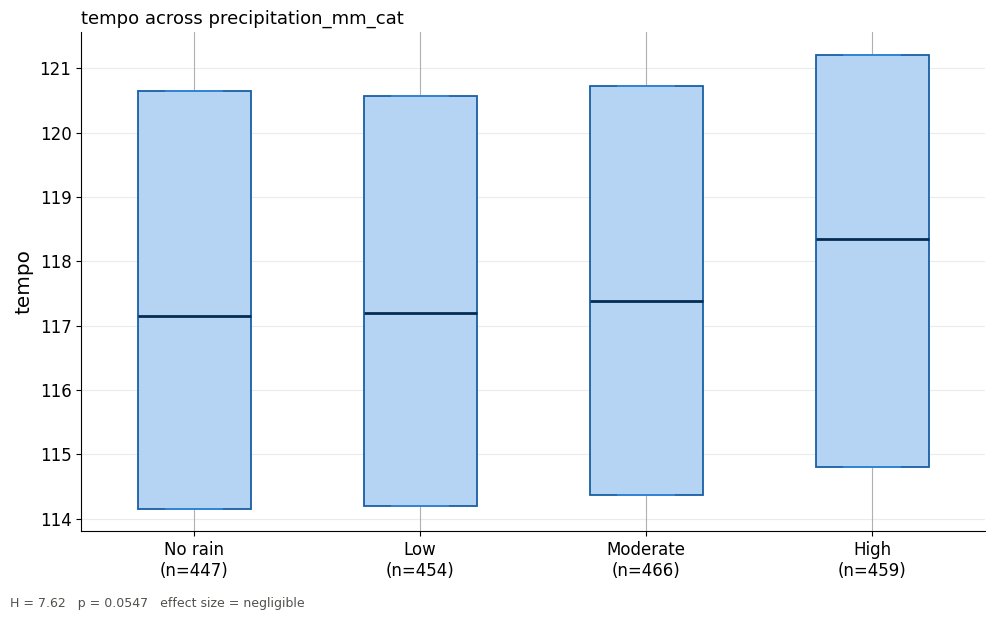

In [242]:
Image(os.path.join(RESULTS_DIR, "kruskal_report_tempo.png"))

- **Interpretation**
There was no statistically significant effect of precipitation type on the tempo according to the Kruskal-Wallis test (H = 7.62, p = 0.0547), just barely missing the standard threshold for significance, with an extremely small effect size (ε² = 0.0042), which means that the variable explains virtually none of the variance in the tempo.

Because of the lack of a significant effect in the omnibus test, no post-hoc analysis of group differences was conducted. Absence of significant differences indicates that the effect of the threshold for the high precipitation days seen before does not stand up to the scrutiny of daily aggregated data.

Nevertheless, there was a very weak but statistically significant positive correlation between the amount of precipitation and tempo according to the Spearman correlation (ρ = 0.0607, p = 0.0095, 95% CI [0.0148, 0.1062]). The confidence interval is completely above zero, providing 95% confidence about the direction of the relationship despite its extreme weakness – practically, one could not attribute any importance to the impact of precipitation on tempo.

The median tempo increased from 117.16 (No rain) to 118.35 BPM (High), for a total increase of +1.19 BPM. Even though the effect is statistically significant, its practical value



### **2.4 Energy**

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 2.16, p = 0.5407 **not significaant** |
| Effect size | ε² = 0.0012  **negligible** |
| Post-hoc | None (omnibus test not significant) |
| Spearman rho | −0.0243, p = 0.2991, 95% CI [−0.0701, 0.0216] |
| Direction | **negative** (energy decreases slightly with precipitation), but not significant |

Energy is completely unaffected by precipitation neither the categorical nor the continuous test reaches significance. Moreeover, the 95% confidence interval for the relationship between the variables [−0.0701, 0.0216] contains the value zero  there is sufficient evidence for a slight positive and negative association, which again is not sufficient to determine any particular direction.

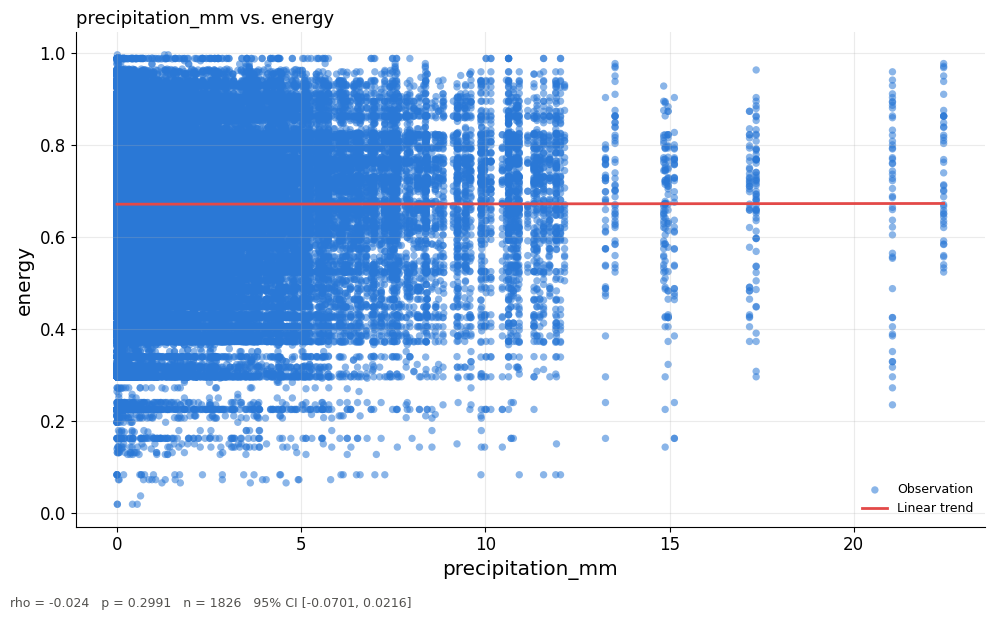

In [243]:
Image(os.path.join(RESULTS_DIR, "spearman_report_energy.png"))

The nearly flat trend line supports the null result, indicating no meaningful monotonic relationship between precipitation and energy across the full range of precipitation values. and additionally, Post-hoc was not conducted as the omnibus test not significant.

### 2.5 Valence

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 4.38, p = 0.2233  **not significant** |
| Effect size | ε² = 0.0024  **negligible** |
| Post-hoc | **none** (omnibus test not significant) |
| Spearman rho | 0.0148, p = 0.5266, 95% CI [−0.0311, 0.0607] |
| Direction | **positive** (valence increases slightly with precipitation), but not significant |

Precipitation has no detectable effect on valence, consistent with RQ1's finding that weather effects on valence are largely seasonal confounds. Post-hoc was not conducted as the omnibus test not significant. Even looking at the CI the relationship between the variables contains zero there is sufficient evidence for a slight positive and negative association, which again is not sufficient to determine any particular direction.

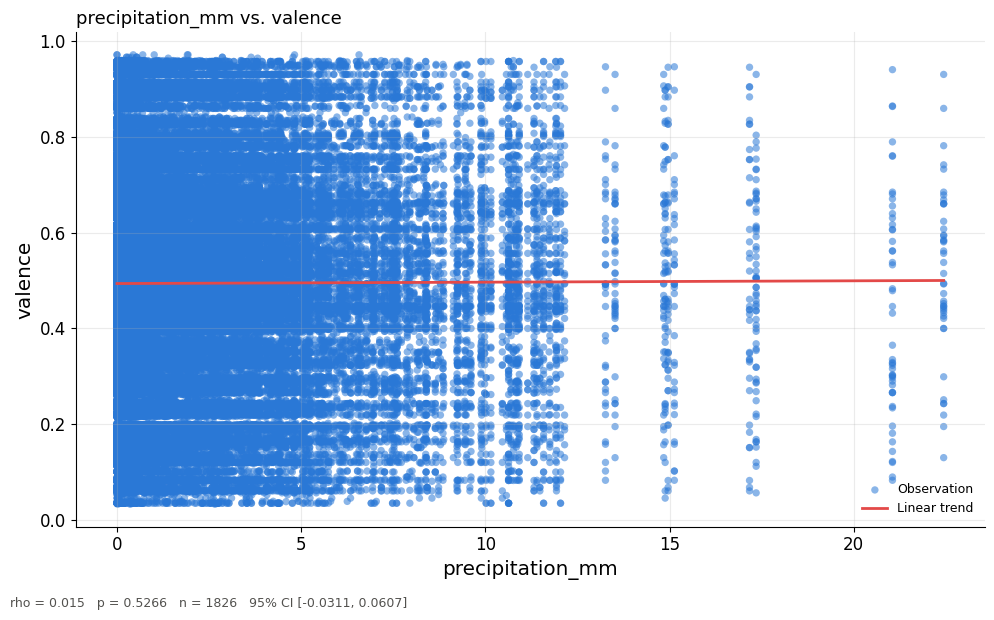

In [244]:
Image(os.path.join(RESULTS_DIR, "spearman_report_valence.png"))

### 3. Hypothesis falsification 
The original problem presented precipitation as a factor that led to a preference shift from Acoustic to High-Energy (or even vice versa). **However, this interpretation is not consistent with the data:**

- **Energy** demonstrates no association with precipitation 
  (H = 2.16, p = 0.5407; rho = −0.0243, p = 0.2991). The preference shift away from acoustic music on rainy days is **not** followed by a preference shift towards high-energy music.
- **Acousticness** demonstrates no significant decline on rainy days after correcting for pseudoreplication (H = 5.36, p = 0.1473; rho = −0.0454, p = 0.0523). The earlier significant association disappears entirely once daily data are used.

Only the significant associations (danceability, and possibly tempo) persist, and these persist only due to the remaining statistical power from the daily sample (n = 1,826). Even then, the effect sizes remain negligible. Refer to Section 4 (Caveats) for more details.

### Cross-reference to RQ8
In light of the minimal and largely non‑significant effects identified, especially the disappearance of the acousticness effect and the contradictory impact on tempo (significant in Spearman but not in Kruskal‑Wallis), one might ask whether rainfall has an independent impact on music choice or whether it acts as a proxy for the effects of seasonality (rainy months in Germany are generally confined to autumn and winter seasons that may independently impact acoustic and danceable tracks).

**RQ8 addresses this question** by testing the additional value of weather variables above and beyond the calendar month variable that can be considered a proxy for seasonality. If the weak effects identified in RQ2 (primarily danceability, and the borderline tempo effect) disappear when season is controlled for, it would indicate that seasonality, rather than rainfall, explains the small changes noted here. Given that acousticness is no longer significant, this question becomes even more pertinent for understanding the remaining minimal associations.

---
## 4. Caveats

The categorization of precipitation was done using percentiles from the dataset instead of fixed daily precipitation amounts as it allows for even distribution of categories, shows the relative precipitation amounts, and is commonly used in the climate science field. The High category, therefore, contains 25% of the wettest days in the dataset, but it does not give a meteorological definition of heavy rain. Since there is no established classification of daily precipitation (Most studies classify precipitation in terms of mm within a very short time period – e.g. mm/10min or mm/60min including those by DWD), this classification method can be seen as a viable solution, although it may lessen the influence of intense rainfall.


**Negligible effect sizes** are observed Despite statistical significance for danceability (and the Spearman correlation for tempo), the effect sizes ε² are very low (≤ 0.0057), and all values of Spearman are also very low (|ρ| ≤ 0.080). With n = 1,826 days, the statistical power is sufficient for detecting only very small effect sizes; however, precipitation has virtually no effect on any acoustic parameter studied.


Difference between statistical and practical significance: The median differences are very low across categories, and for acousticness, they cease being significant.

| Feature | No rain | High | Difference |
|---|---|---|---|
| Acousticness | 0.2008 | 0.1982 | 0.0026 |
| Danceability | 0.6854 | 0.6811 | 0.0043 |
| Tempo (BPM) | 117.16 | 118.35 | 1.19 |

**Energy not significantly related to precipitation:** The original research hypothesis involved a comparison between 'Acoustic' and 'High-Energy' songs. There is no significant relationship found between energy and precipitation  both categorical and continuous versions are not significant. Preference for high-energy songs when it rains is not associated with preference against acoustic songs.

**Inconsistency of Dunn's post-hoc analysis:** Danceability is the only feature that has a consistent impact in both Kruskal-Wallis and Spearman tests, although the effect size is minimal (ε² = 0.0057, |ρ| = 0.080). Tempo has shown statistically significant Spearman correlation (ρ = 0.061, p = 0.0095) but Kruskal‑Wallis passed very close to significance (p = 0.0547) indicating that the effect is very weak and inconsistent. Post-hoc pairwise analysis of danceability shown that only No rain vs High comparison proved to be significant (p = 0.0074) while all other comparisons were not significant. This limited and inconsistent result suggest that the relationships observed may actually be reliant on the extreme tail of the precipitation distribution making the conclusion about any strong connection hardly possible.

---
## 5. Takeaway

There is also a weakly significant shift in music choice during precipitation: danceability is slightly decreased, while tempo is marginally increased, and acousticness is not changed significantly when the analysis is carried out using independent days (H = 5.36, p = 0.1473; ρ = -0.0454, p = 0.0523). However, energy is not influenced at all (H = 2.16, p = 0.5407; ρ = -0.0243, p = 0.2991), and this is inconsistent with both 'rain → less acoustic music' and 'rain → more high-energy music' pattern, thus rejecting our hypothesis.

Effect sizes are very low (ε² ≤ 0.0057; |ρ| ≤ 0.080), meaning that the percentage of variance explained by rainfall is below 1%. Using 1,826 independent daily observations that accounted for pseudoreplication, we found no significance of the effects on acousticness at all.

The initial dichotomy of 'acoustic' and 'high-energy' music has been disproven by results. Rain does not influence the acoustic features of German Top Charts in Spotify in any